# Day 28: Sales Analysis
Ad-hoc analysis, statistics and visualizations on the sales warehouse.

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
con = sqlite3.connect("../data/warehouse.db")

## 1. Load data (one joined table)

In [2]:
df = pd.read_sql('''
    SELECT f.*, d.full_date, d.year, d.quarter, d.month, d.day_name, d.is_weekend,
           p.category, p.product_name, c.segment, c.region
    FROM fact_sales f
    JOIN dim_date d     ON f.date_key = d.date_key
    JOIN dim_product p  ON f.product_key = p.product_key
    JOIN dim_customer c ON f.customer_key = c.customer_key
''', con)
df["full_date"] = pd.to_datetime(df["full_date"])
df["profit"] = df["revenue"] - df["cost"]
df.head()

,sale_id,date_key,customer_key,product_key,quantity,discount,revenue,cost,full_date,year,quarter,month,day_name,is_weekend,category,product_name,segment,region,profit
0,1,20230628,176,9,2,0.0,1467.44,1119.70,2023-06-28,2023,2,6,Wed,0,Electronics,Electronics Item 9,Consumer,East,347.74
1,2,20230701,417,8,1,0.0,223.47,149.94,2023-07-01,2023,3,7,Sat,1,Electronics,Electronics Item 8,Consumer,North,73.53
2,3,20241025,196,33,5,0.0,665.45,436.30,2024-10-25,2024,4,10,Fri,0,Clothing,Clothing Item 3,Consumer,North,229.15
3,4,20230125,486,34,3,0.0,290.61,180.09,2023-01-25,2023,1,1,Wed,0,Clothing,Clothing Item 4,Small Business,East,110.52
4,5,20230629,158,9,4,0.0,2934.88,2239.40,2023-06-29,2023,2,6,Thu,0,Electronics,Electronics Item 9,Corporate,North,695.48


In [3]:
df.describe().round(2)

,sale_id,date_key,customer_key,product_key,quantity,discount,revenue,cost,full_date,year,quarter,month,is_weekend,profit
count,24148.00,24148.00,24148.00,24148.00,24148.00,24148.00,24148.00,24148.00,24148,24148.00,24148.00,24148.00,24148.00,24148.00
mean,12074.50,20236264.67,250.89,20.53,3.00,0.04,662.34,469.51,2024-01-31 14:34:34.010270,2023.56,2.61,6.85,0.29,192.84
min,1.00,20230101.00,1.00,1.00,1.00,0.00,5.09,4.84,2023-01-01 00:00:00,2023.00,1.00,1.00,0.00,0.25
25%,6037.75,20230809.00,123.00,10.00,2.00,0.00,147.48,103.60,2023-08-09 00:00:00,2023.00,2.00,4.00,0.00,40.50
50%,12074.50,20240209.00,252.00,21.00,3.00,0.00,359.44,250.80,2024-02-09 00:00:00,2024.00,3.00,7.00,0.00,100.65
75%,18111.25,20240803.00,378.00,30.00,4.00,0.05,893.88,656.00,2024-08-03 00:00:00,2024.00,4.00,10.00,1.00,248.90
max,24148.00,20241231.00,500.00,40.00,5.00,0.20,4128.60,3041.05,2024-12-31 00:00:00,2024.00,4.00,12.00,1.00,1277.30
std,6971.07,4979.29,145.61,11.56,1.42,0.05,751.90,542.10,NaN,0.50,1.14,3.55,0.45,231.88


In [4]:
df.isna().sum().sum()   # missing values

np.int64(0)

## 2. Statistical analysis

### 2.1 Does discount hurt profit per order? (t-test)

In [5]:
no_disc = df[df.discount == 0]["profit"]
disc = df[df.discount > 0]["profit"]
t, p = stats.ttest_ind(no_disc, disc, equal_var=False)
print(f"Avg profit, no discount: {no_disc.mean():.2f}")
print(f"Avg profit, discounted : {disc.mean():.2f}")
print(f"t = {t:.2f}, p-value = {p:.4f}")

Avg profit, no discount: 219.73
Avg profit, discounted : 152.79
t = 23.45, p-value = 0.0000


### 2.2 Does average order value differ across regions? (ANOVA)

In [6]:
groups = [g["revenue"].values for _, g in df.groupby("region")]
f, p = stats.f_oneway(*groups)
print(f"F = {f:.2f}, p-value = {p:.4f}")
df.groupby("region")["revenue"].mean().round(2)

F = 0.62, p-value = 0.6026


region
East     661.21
North    669.85
South    652.75
West     666.19
Name: revenue, dtype: float64

### 2.3 Weekday vs weekend order value

In [7]:
wk = df[df.is_weekend == 0]["revenue"]
we = df[df.is_weekend == 1]["revenue"]
t, p = stats.ttest_ind(wk, we, equal_var=False)
print(f"Weekday avg: {wk.mean():.2f} | Weekend avg: {we.mean():.2f} | p-value = {p:.4f}")

Weekday avg: 661.58 | Weekend avg: 664.23 | p-value = 0.8041


### 2.4 Correlation

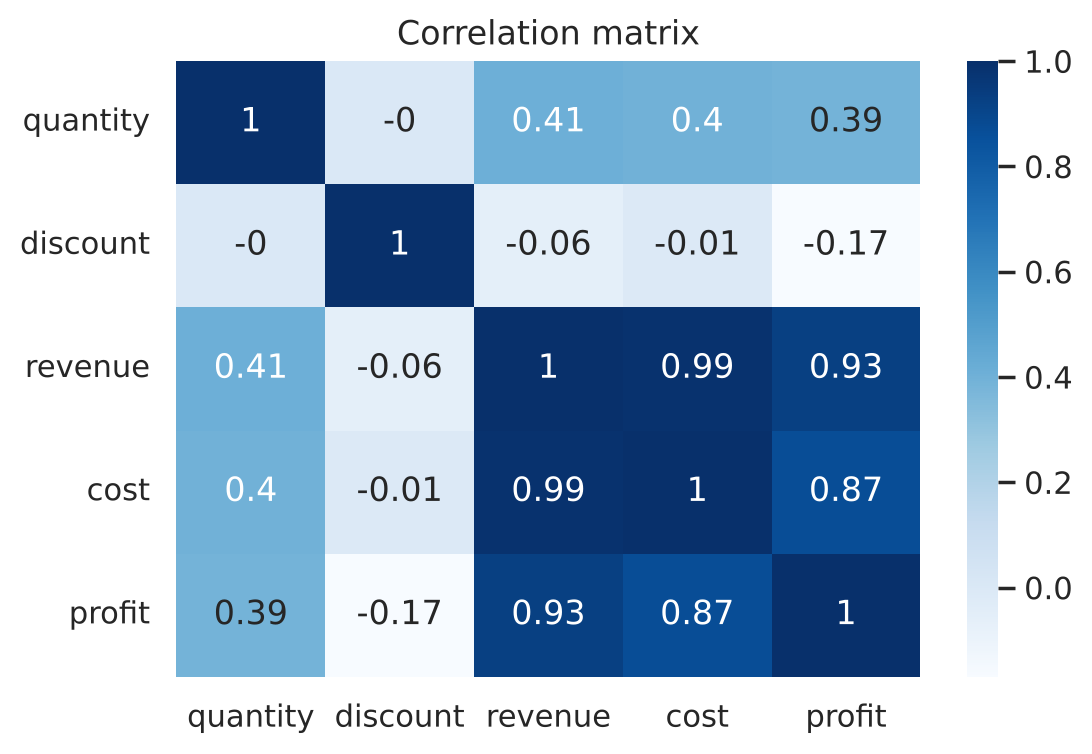

In [8]:
corr = df[["quantity", "discount", "revenue", "cost", "profit"]].corr().round(2)
plt.figure(figsize=(6, 4))
sns.heatmap(corr, annot=True, cmap="Blues")
plt.title("Correlation matrix")
plt.show()

## 3. Visualizations

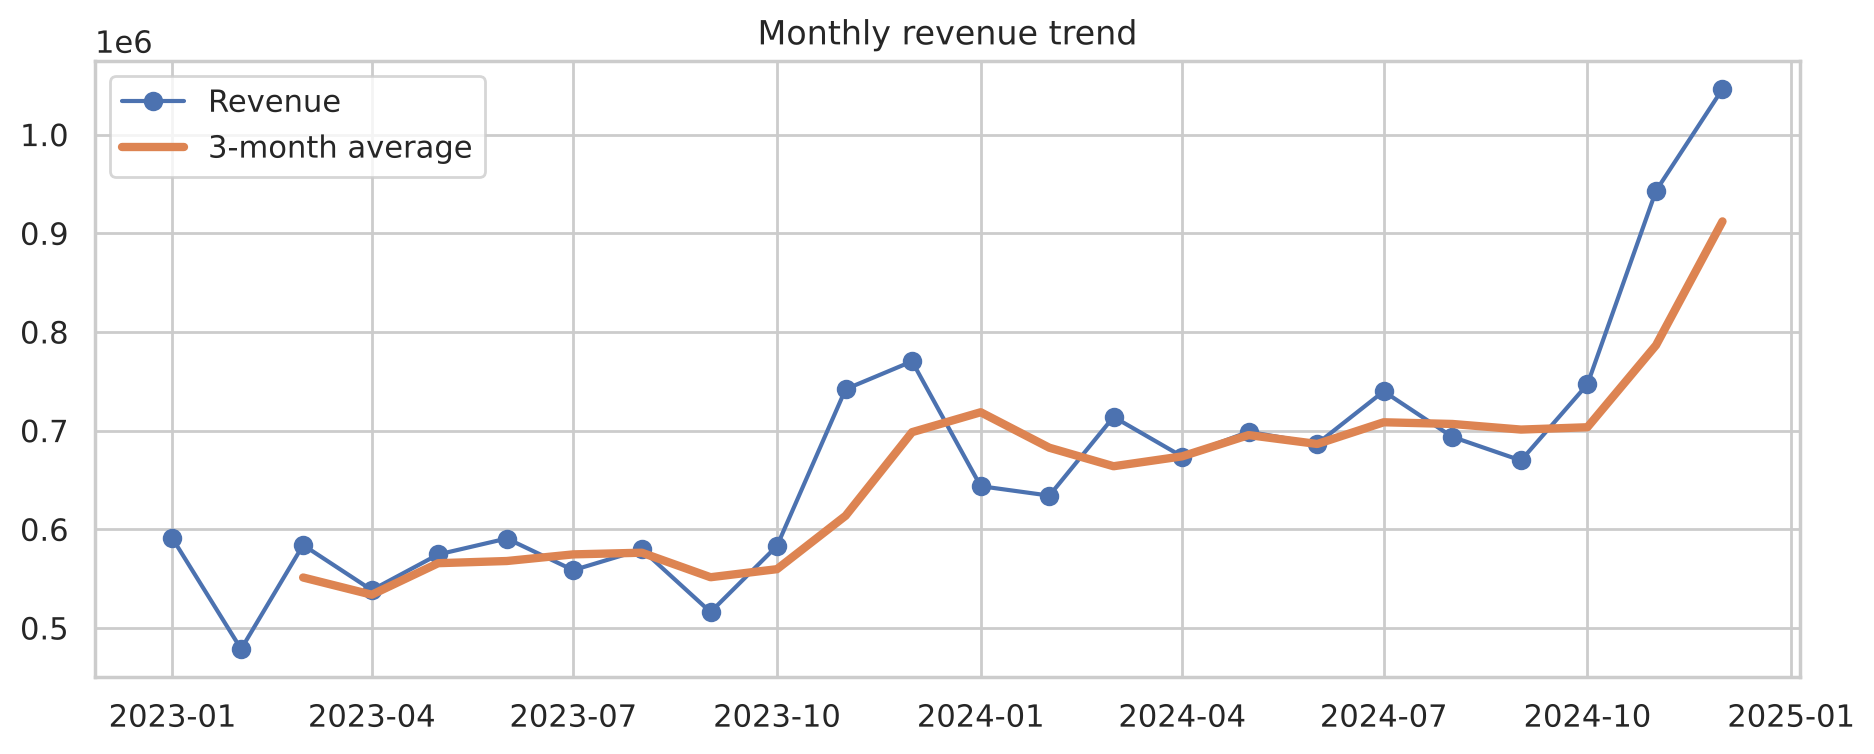

In [9]:
# Monthly revenue trend with 3-month rolling average
monthly = df.groupby(df["full_date"].dt.to_period("M"))["revenue"].sum()
monthly.index = monthly.index.to_timestamp()

plt.figure(figsize=(11, 4))
plt.plot(monthly, marker="o", label="Revenue")
plt.plot(monthly.rolling(3).mean(), linewidth=3, label="3-month average")
plt.title("Monthly revenue trend")
plt.legend()
plt.show()

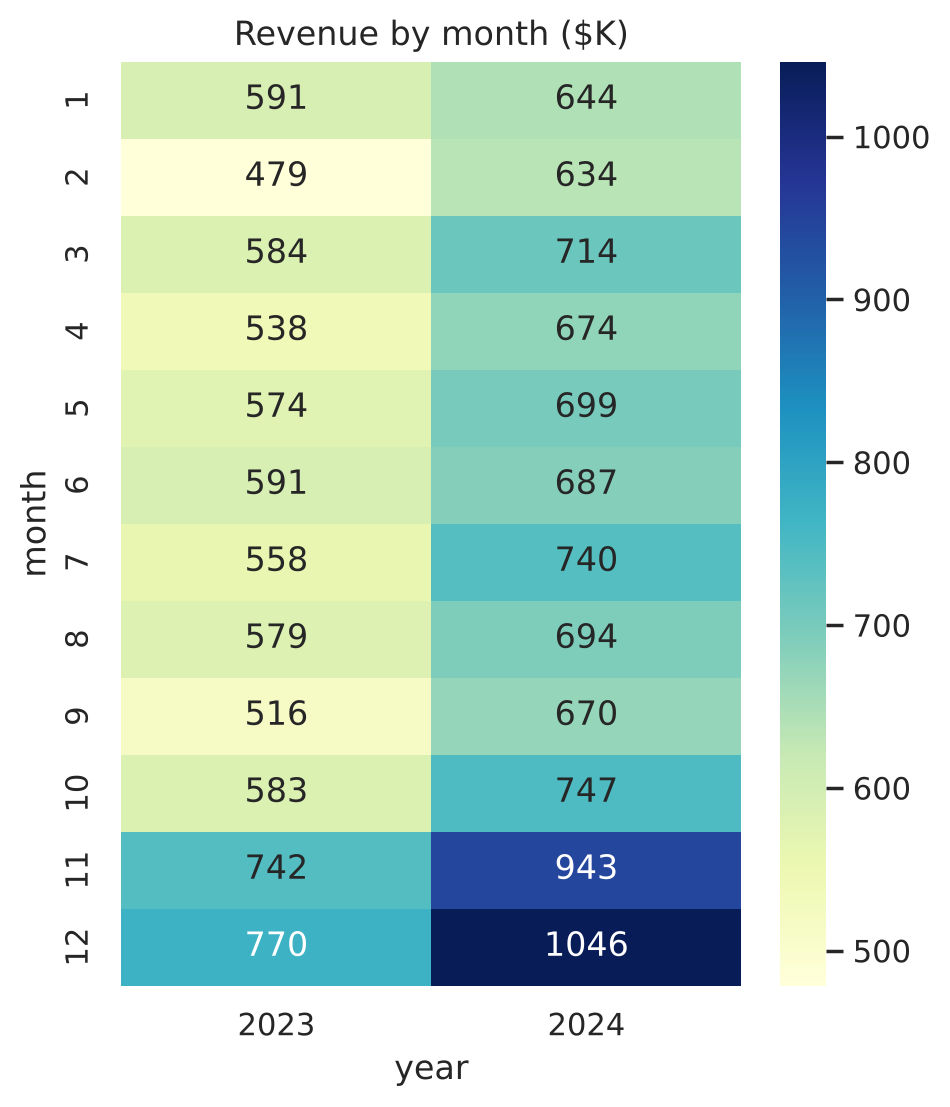

In [10]:
# Seasonality heatmap: month x year
pivot = df.pivot_table(index="month", columns="year", values="revenue", aggfunc="sum")
plt.figure(figsize=(5, 6))
sns.heatmap(pivot / 1000, annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("Revenue by month ($K)")
plt.show()

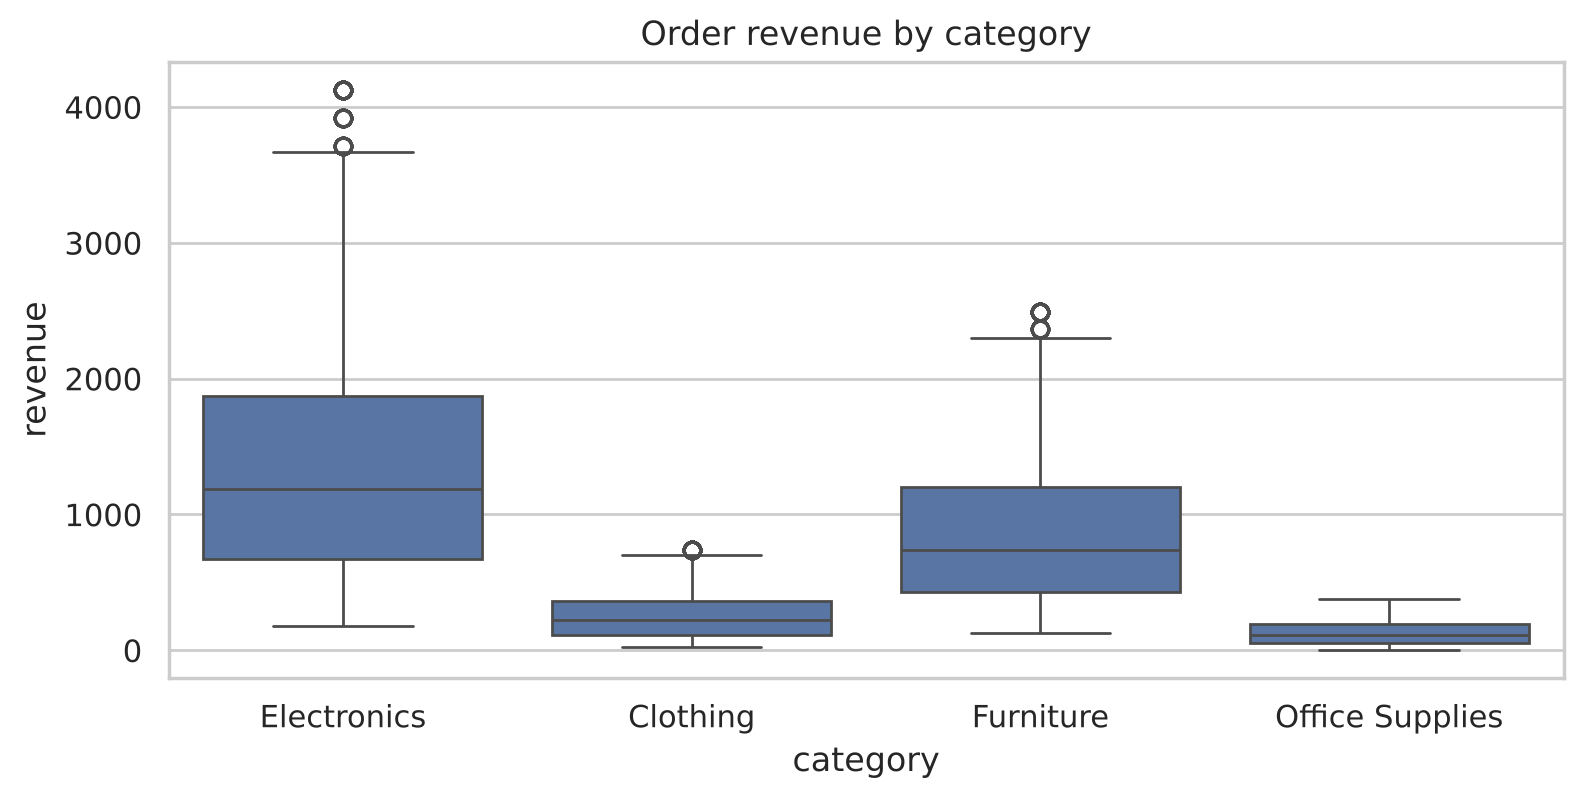

In [11]:
# Revenue distribution by category
plt.figure(figsize=(9, 4))
sns.boxplot(data=df, x="category", y="revenue")
plt.title("Order revenue by category")
plt.show()

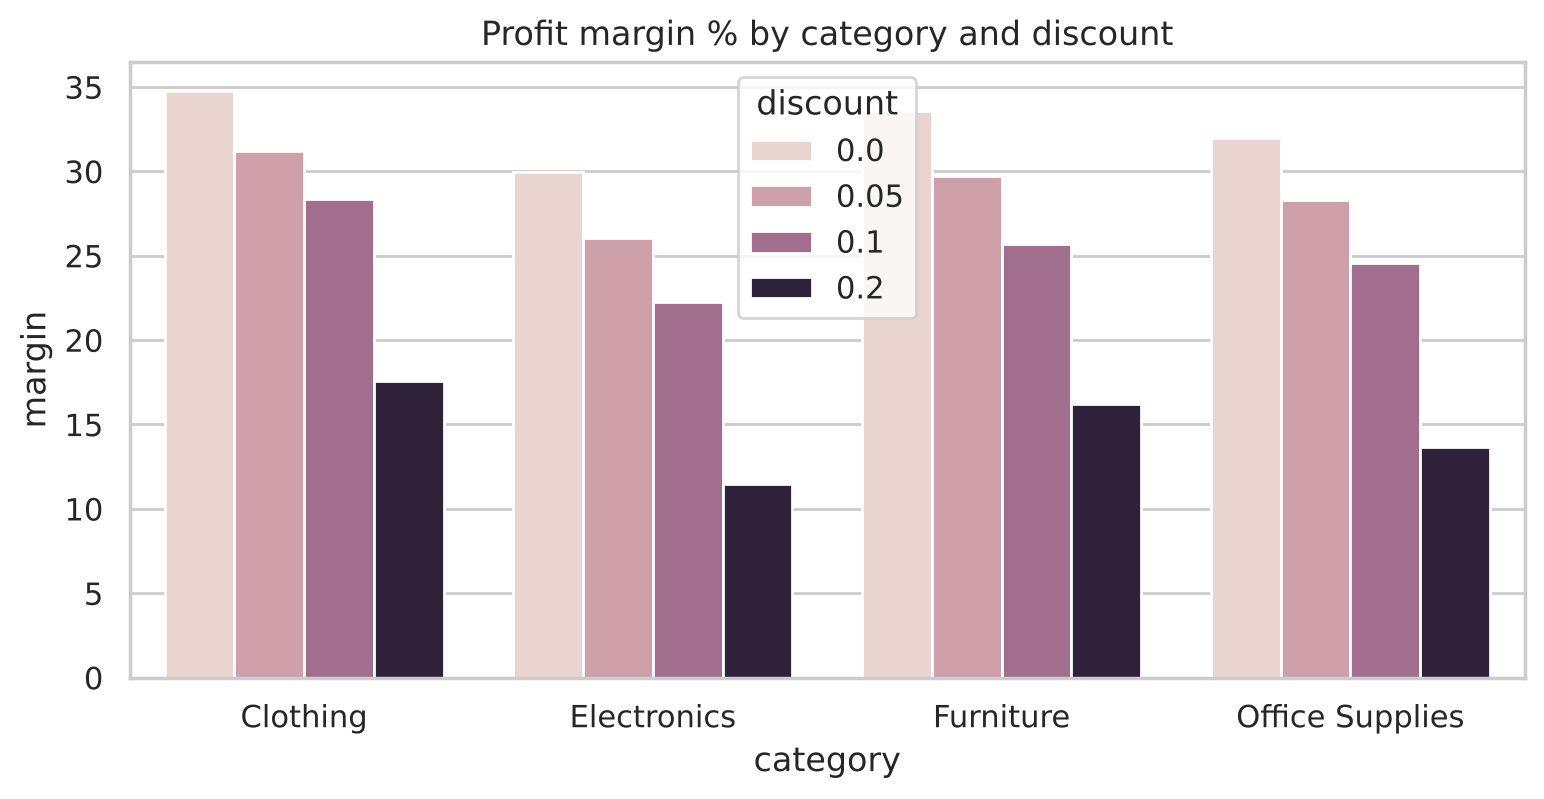

In [12]:
# Profit margin by category and discount level
m = df.groupby(["category", "discount"]).apply(lambda x: x.profit.sum() / x.revenue.sum() * 100).reset_index(name="margin")
plt.figure(figsize=(9, 4))
sns.barplot(data=m, x="category", y="margin", hue="discount")
plt.title("Profit margin % by category and discount")
plt.show()

## 4. Customer concentration (Pareto)

Top 20% of customers generate 27.6% of revenue


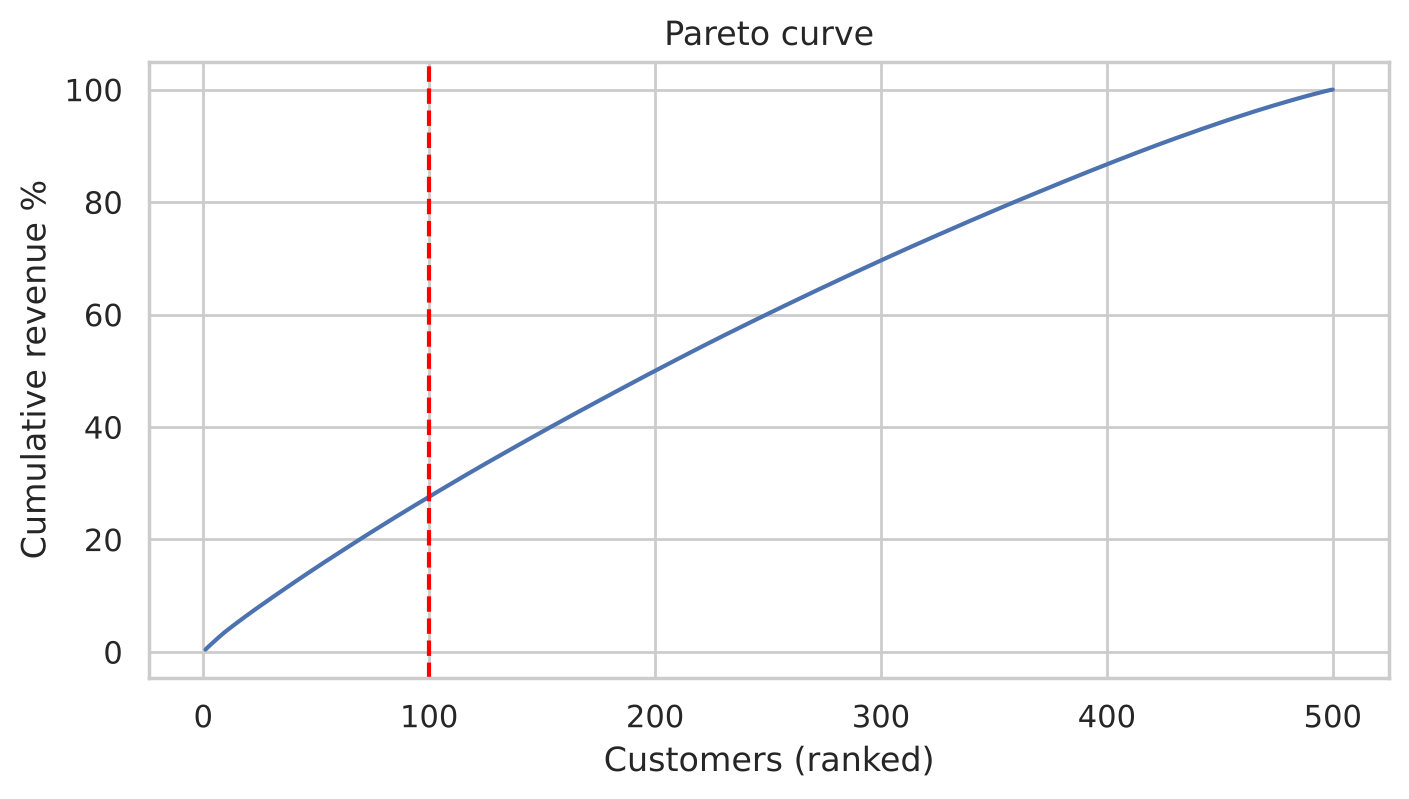

In [13]:
cust = df.groupby("customer_key")["revenue"].sum().sort_values(ascending=False)
cum_pct = cust.cumsum() / cust.sum() * 100
top20 = int(len(cust) * 0.2)
print(f"Top 20% of customers generate {cum_pct.iloc[top20 - 1]:.1f}% of revenue")

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cust) + 1), cum_pct.values)
plt.axvline(top20, color="red", linestyle="--")
plt.xlabel("Customers (ranked)"); plt.ylabel("Cumulative revenue %")
plt.title("Pareto curve")
plt.show()

## 5. Simple customer segments (high / medium / low spend)

In [14]:
spend = df.groupby("customer_key")["revenue"].sum()
tier = pd.qcut(spend, 3, labels=["Low", "Medium", "High"])
summary = spend.groupby(tier, observed=True).agg(["count", "mean", "sum"]).round(0)
summary

,count,mean,sum
revenue,,,
Low,167,23437.0,3913967.0
Medium,166,31430.0,5217440.0
High,167,41095.0,6862881.0


## 6. Year-over-year growth

In [15]:
yoy = df.groupby("year")["revenue"].sum()
print(yoy.round(0))
print(f"YoY growth: {(yoy[2024] / yoy[2023] - 1) * 100:.1f}%")

year
2023    7105180.0
2024    8889108.0
Name: revenue, dtype: float64
YoY growth: 25.1%
